# 07 — Conference results from observed artifacts

**Purpose:** Compile source counts, split sizes, hardware, training details and WBC localization results without invented values.

**Required inputs:** Outputs of earlier notebooks. Missing experiments are shown as `Not available`.

**Saved outputs:** `outputs/paper_results/experiment_summary.md/.csv`, `experiment_metadata.json`, paper figures.

## 1. Load the central configuration

The root is found from the notebook location or the installed package. Set `LEUKEMIA_YOLO_CONFIG` only for synthetic smoke tests or an alternate config.

In [1]:
from pathlib import Path
import os, sys
search = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("LEUKEMIA_YOLO_ROOT"):
    search.insert(0, Path(os.environ["LEUKEMIA_YOLO_ROOT"]))
for candidate in search:
    if (candidate / "config.example.yaml").is_file() and (candidate / "src" / "config.py").is_file():
        sys.path.insert(0, str(candidate))
        break
from src.config import load_config, ensure_outputs
cfg = load_config()
out = ensure_outputs(cfg)
os.chdir(cfg["root"])
print("Project root:", cfg["root"])
print("Configuration:", cfg["config_path"])

Project root: D:\CellCancer\leukemia-yolo
Configuration: D:\CellCancer\leukemia-yolo\config.local.yaml


## 2. Build source-backed summary

Test metrics are accepted only if the dataset and checkpoint hashes match the current completed run.

In [2]:
from src.reporting import build_summary, summary_table, LIMITATION
summary = build_summary(cfg)
display(summary_table(summary))
print(LIMITATION)

,field,observed value
0,dataset description,Kaggle BCCD blood-smear images with pre-define...
1,source images,364
2,source wbc annotations,372
3,split train,205
4,split val,87
5,split test,72
6,model variant,YOLOv8n object detection
7,pretrained weights,yolov8n.pt
8,actual training configuration,{'data': 'D:\\CellCancer\\leukemia-yolo\\data\...
9,hardware os,Windows 10 10.0.26200


The BCCD-based YOLOv8 experiment evaluates leukocyte localization only. Blast classification is a separate future stage trained using leukemia-labeled cell images.


## 3. Show validation training curves

The training results.csv contains validation metrics; test metrics come only from notebook 05.

loss_curves D:\CellCancer\leukemia-yolo\outputs\paper_results\figures\training_loss_curves.png


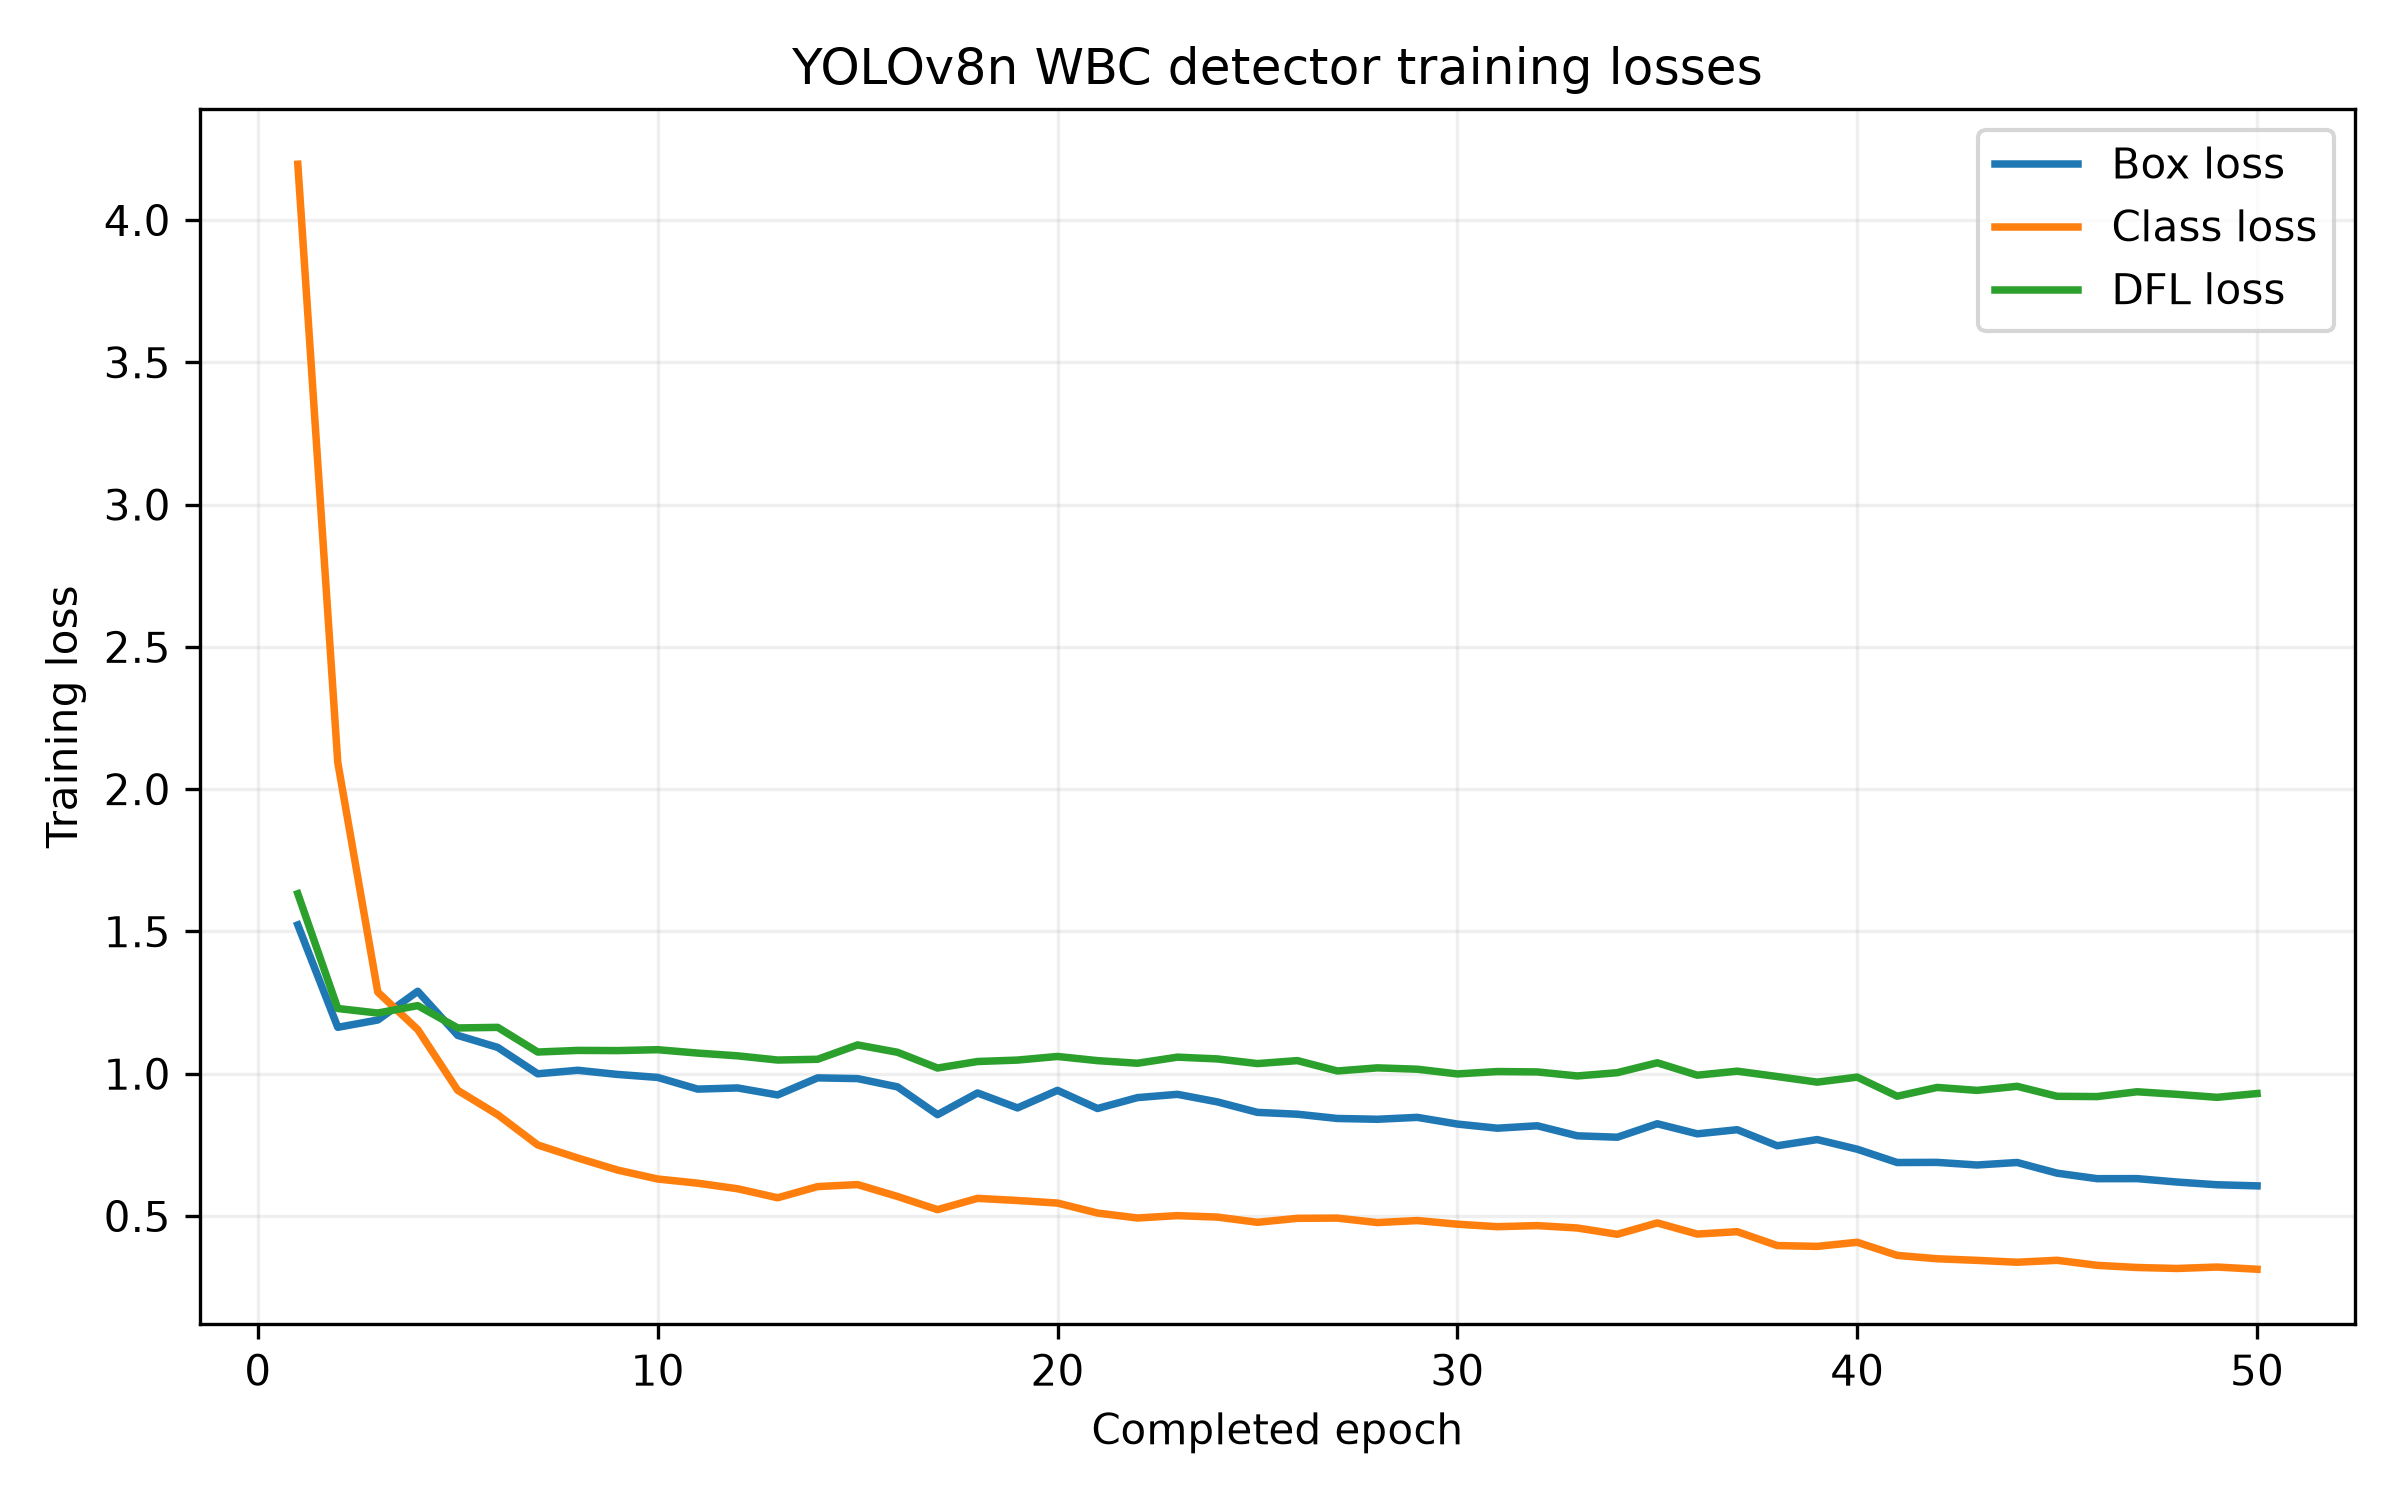

precision_recall_curve D:\CellCancer\leukemia-yolo\outputs\paper_results\figures\BoxPR_curve.png


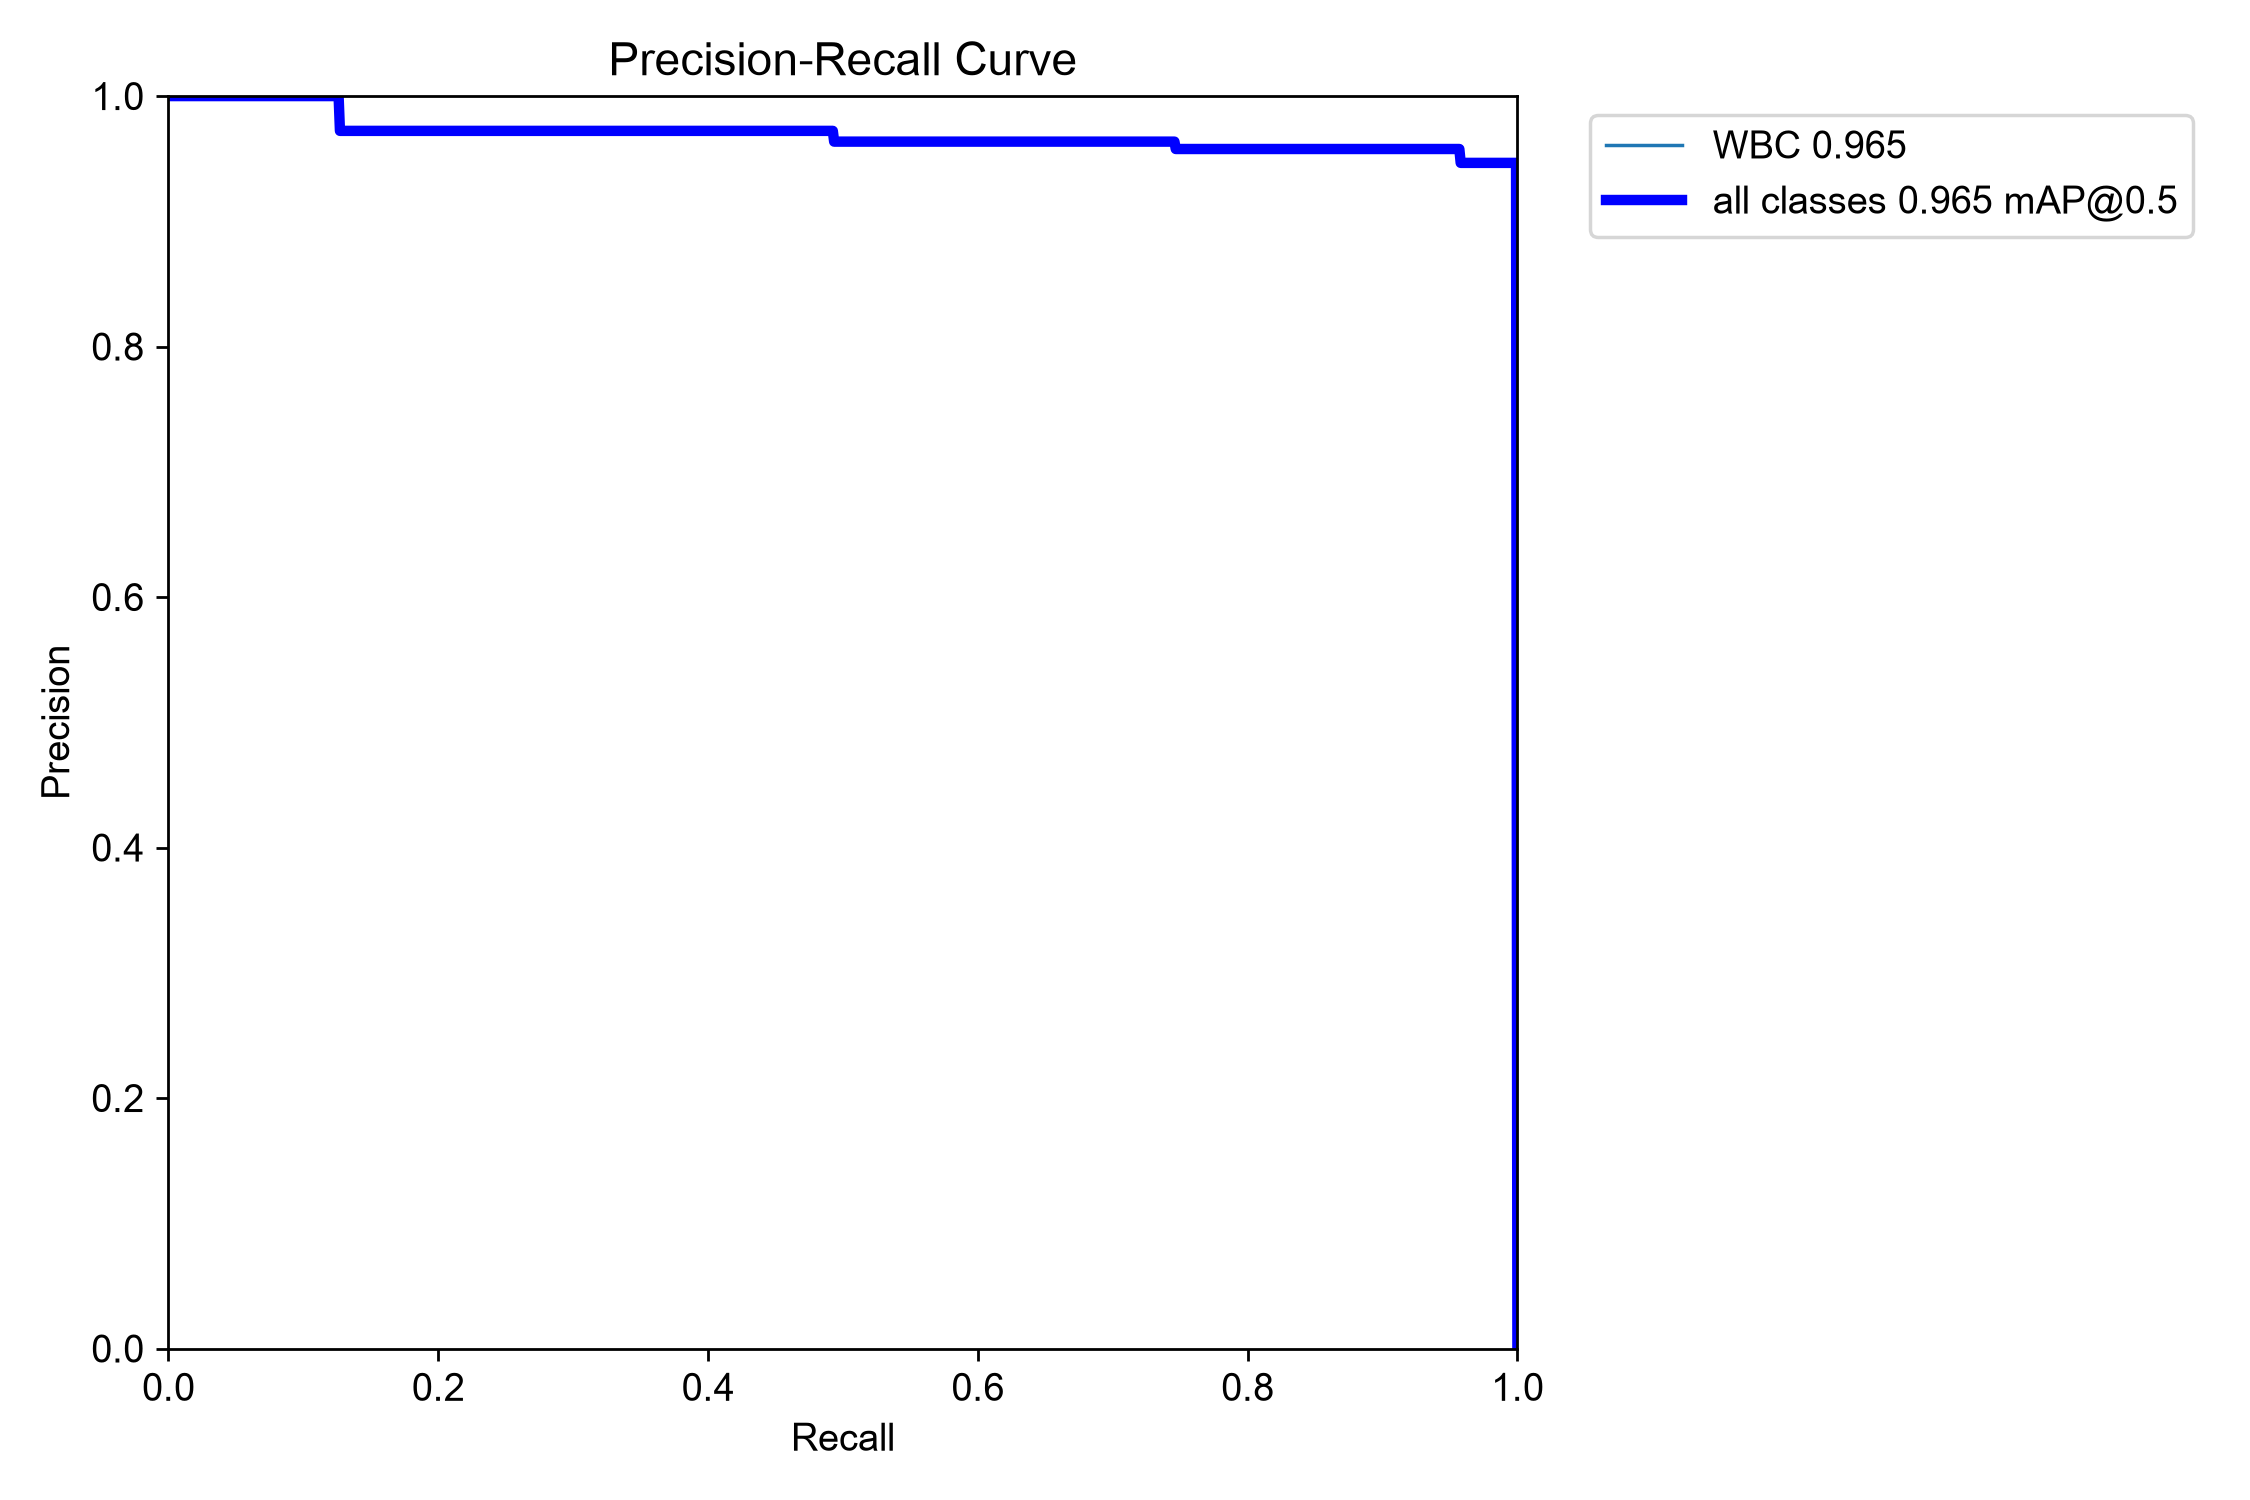

confusion_matrix D:\CellCancer\leukemia-yolo\outputs\paper_results\figures\confusion_matrix.png


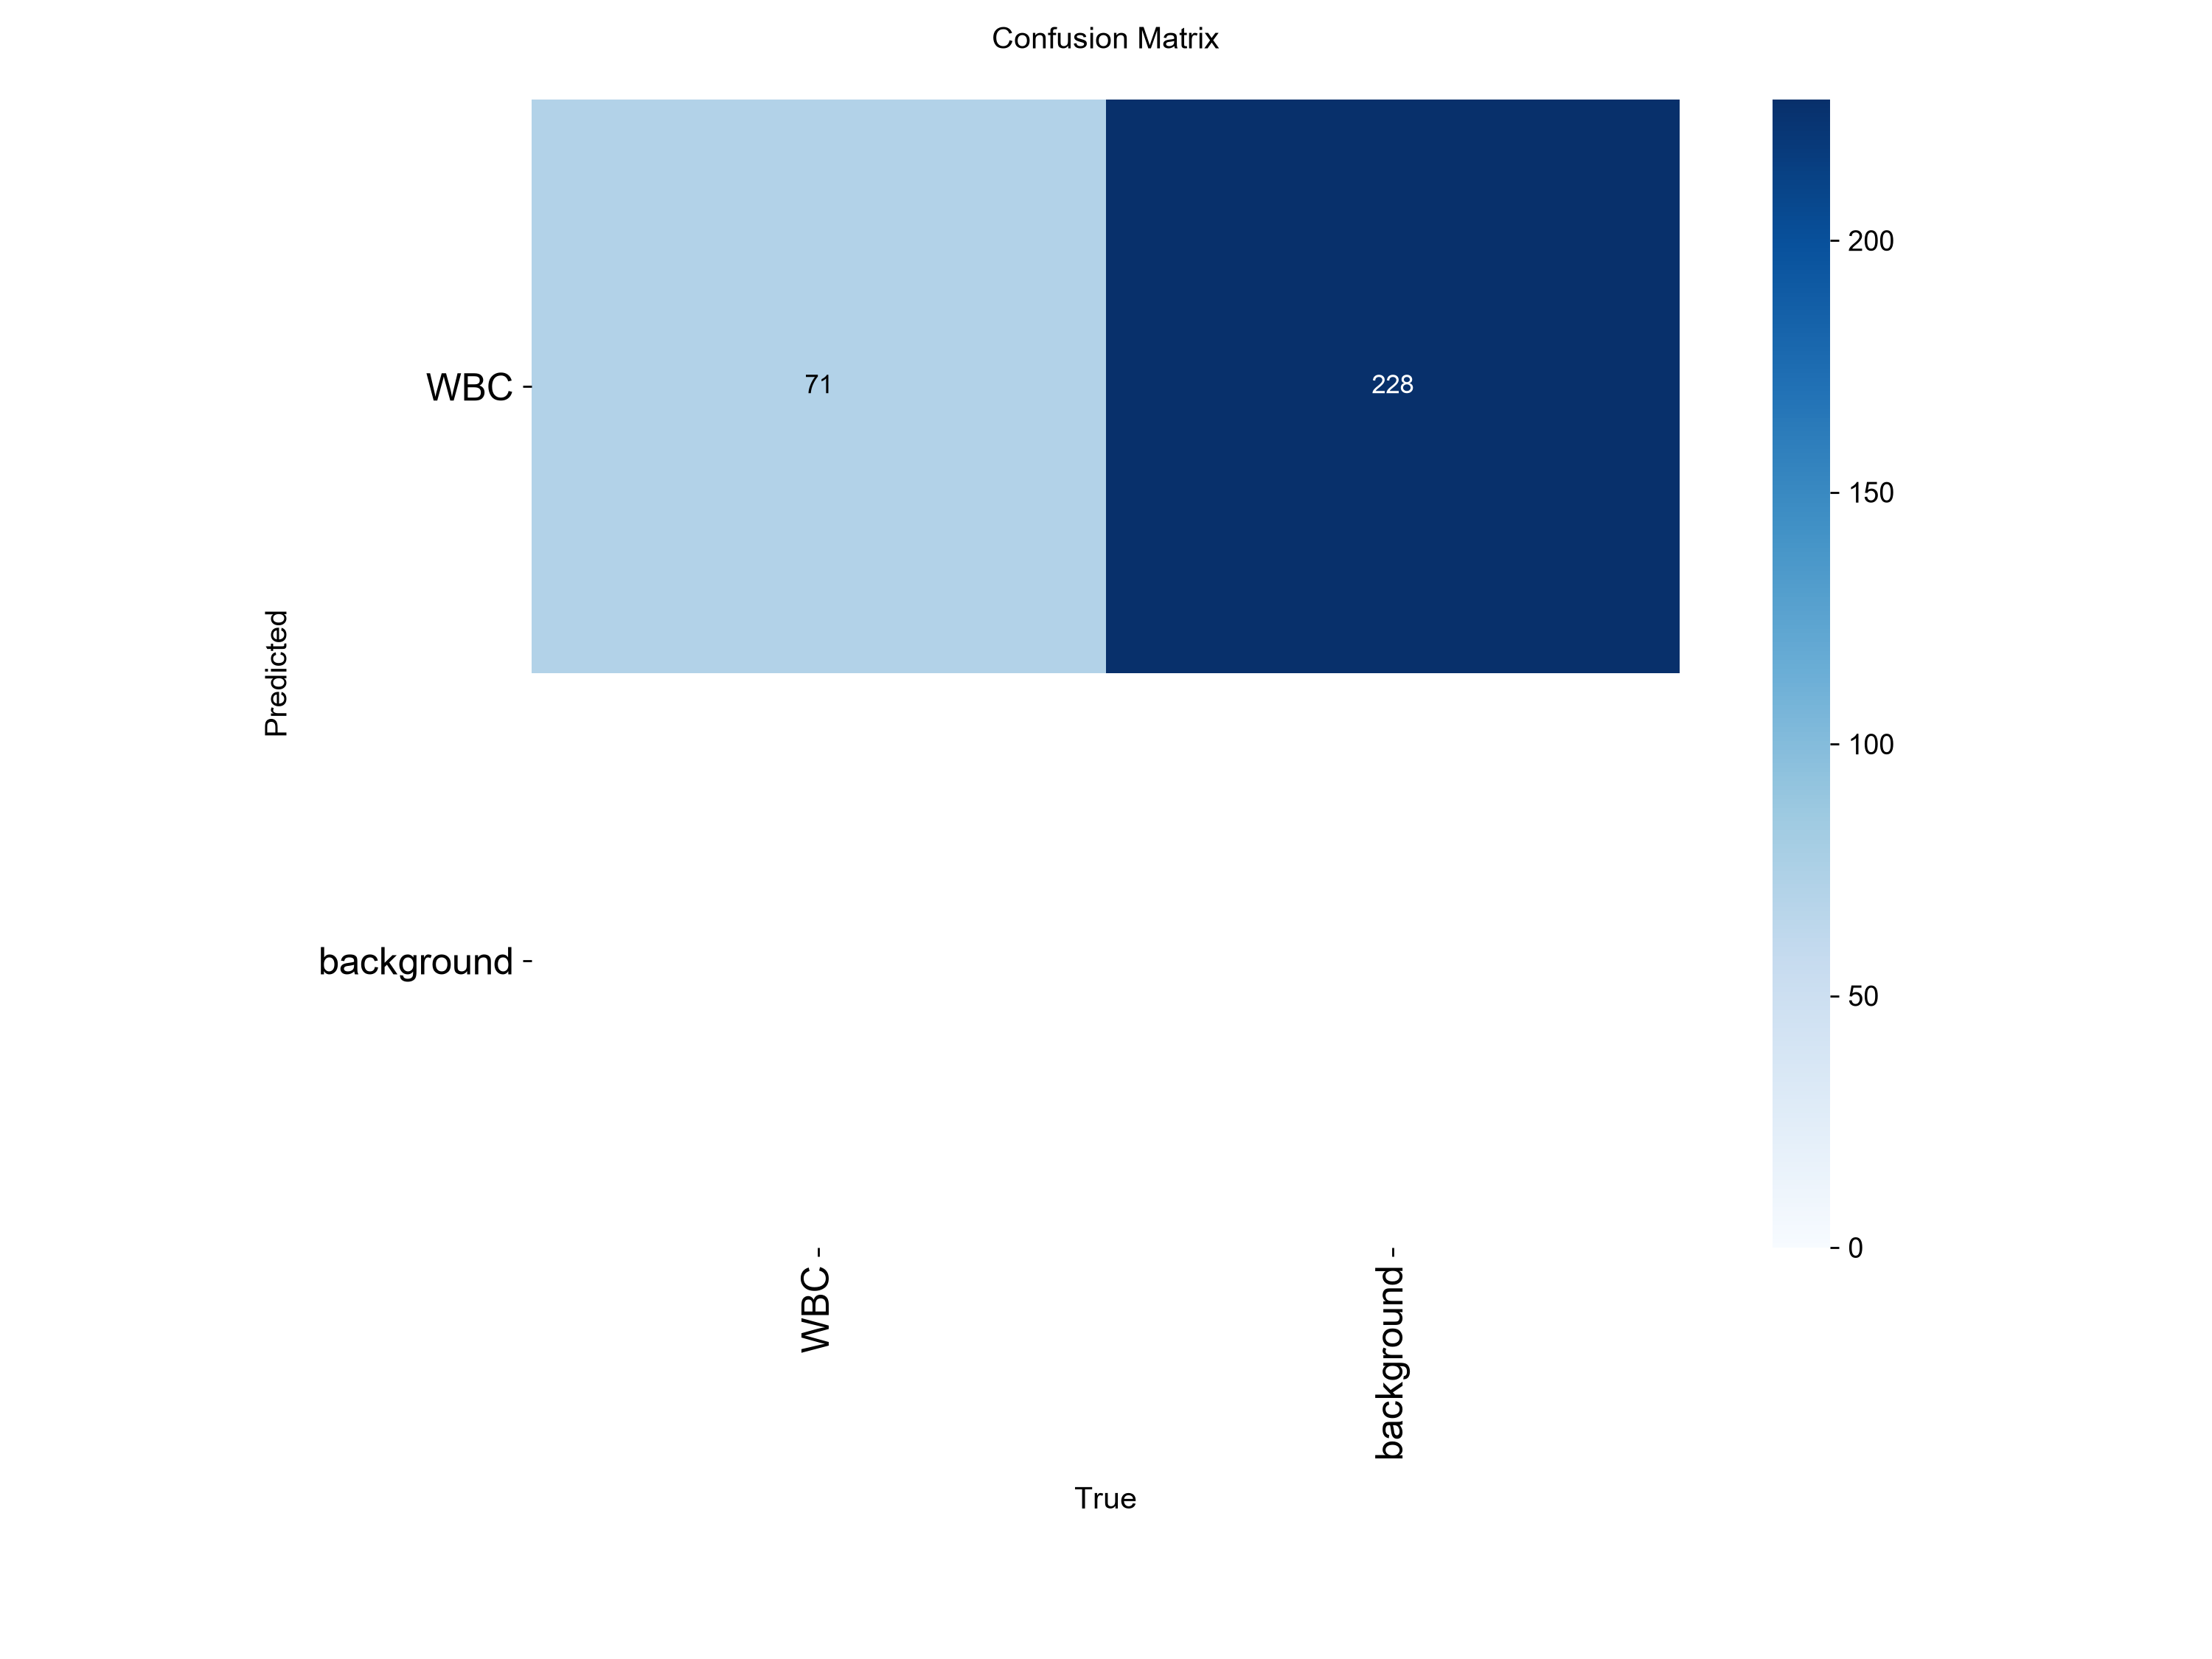

In [3]:
from IPython.display import display, Image as IPImage
for label in ("loss_curves", "precision_recall_curve", "confusion_matrix"):
    artifact = summary[label]
    print(label, artifact)
    if artifact != "Not available" and Path(artifact).is_file():
        display(IPImage(filename=str(artifact)))

## 4. Show example detections

These are WBC localization predictions, without blast or normal cell labels.

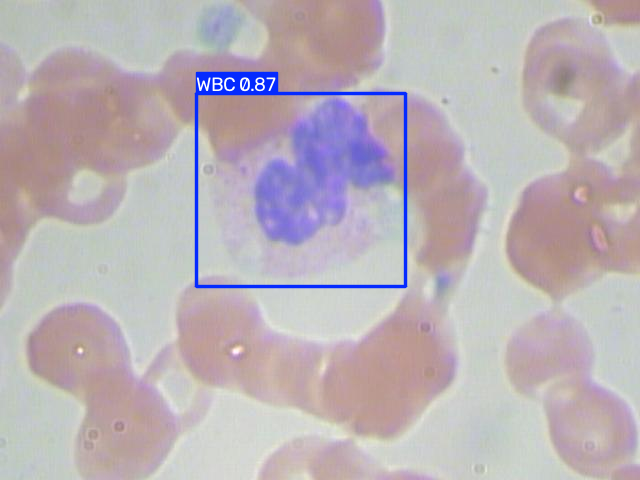

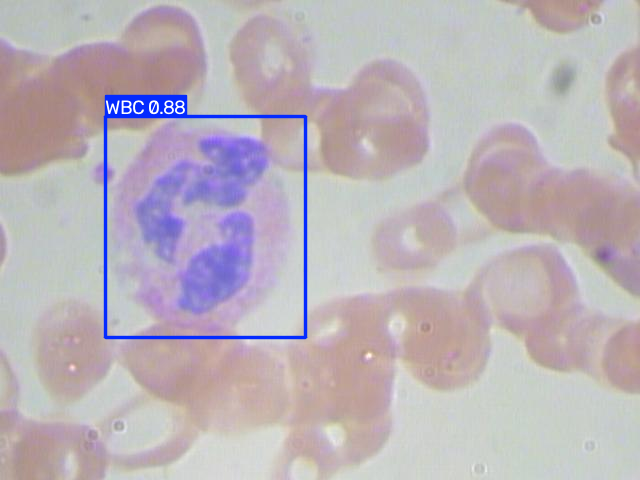

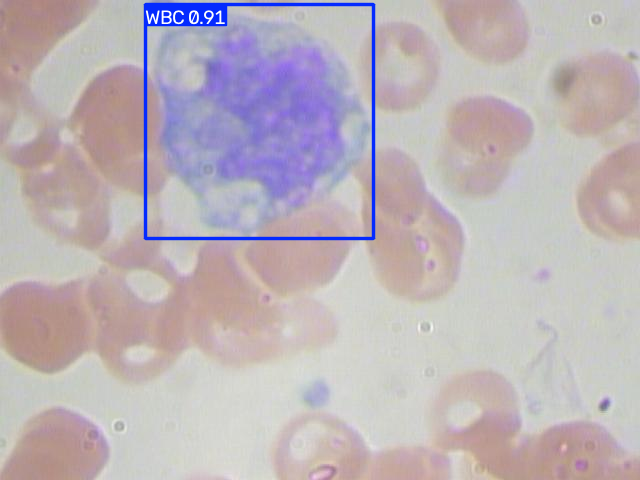

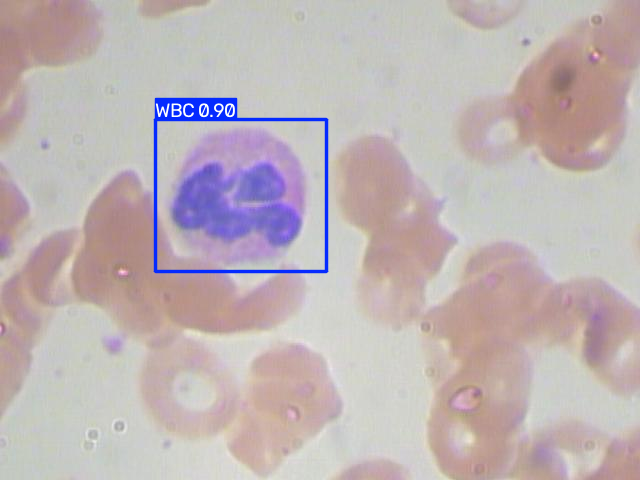

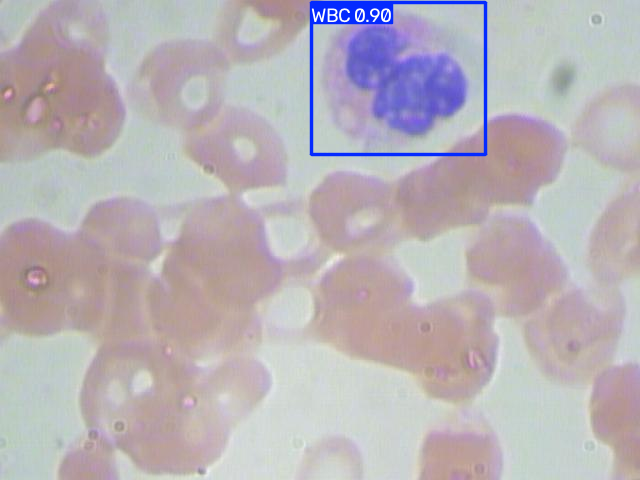

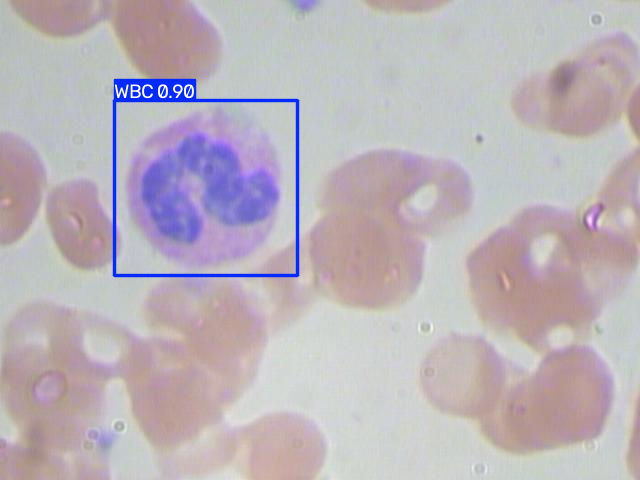

In [4]:
examples = summary["example_detections"]
if examples == "Not available":
    print("Example detections: Not available")
else:
    for path in examples:
        display(IPImage(filename=str(path)))

## 5. Validate export schema

The summary is suitable for drafting a paper only after real data, CUDA training and held-out evaluation are complete.

In [5]:
from src.config import read_json
saved = read_json(out / "paper_results" / "experiment_metadata.json")
assert saved["limitations"] == LIMITATION
assert (out / "paper_results" / "experiment_summary.csv").is_file()
assert (out / "paper_results" / "experiment_summary.md").is_file()
print("PASS — provenance-aware paper tables saved." if saved["test_mAP50"] != "Not available" else
      "WARNING — paper tables saved with unavailable results; complete notebooks 04–06 on the CUDA laptop.")

PASS — provenance-aware paper tables saved.


## Next notebook

Stage 1 ends here. EfficientNet-B3, Grad-CAM and blast quantification require separately labeled leukemia data and are future work.